# 히스토리 트리밍과 실제 요약

이 절은 길어진 대화 기록(히스토리)을 줄이는 두 방법을 견줍니다.
하나는 오래된 대화를 잘라 내는 자르기(트리밍, trimming)입니다.
다른 하나는 오래된 대화를 모델에게 요약시켜 메시지 하나로 남기는 요약하기입니다.

**이 노트북에서 할 일**

1. 시스템 메시지 하나와 대화 메시지 다섯 개로 된 대화 기록을 만듭니다.
2. 최근 대화 둘만 남기고 오래된 대화를 잘라 냅니다.
3. 오래된 대화를 모델로 요약해 요약 메시지 하나로 바꿉니다.
4. 두 기록의 메시지 수와 지킬 말을 코드로 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 6절의 요약 한 번이고 임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 자료 파일은 없고 새로 쓰는 파일도 없습니다.
대화 기록은 이 절에서 손으로 적은 것이고 개인정보는 넣지 않았습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 3초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 읽습니다.
대화 기록을 나누고 오래된 대화를 잘라 내는 자리입니다.
6절 요약하기와 7절 견주기는 실습 시간에 실행합니다.
8절 손 확인과 9절 값 바꿔 보기도 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 대화 기록 시스템 하나와 대화 다섯에서 파란 상자 나누기 split_history로 이어지고 거기서 화살표가 둘로 나뉘어 왼쪽은 파란 상자 요약하기 summarize_history와 보라 상자 요약 모델 gpt-5.4-mini 오래된 대화 셋을 요약을 지나 노란 상자 요약한 기록 메시지 넷으로 가고 오른쪽은 파란 상자 자르기 trim_history 최근 대화 둘만 남김을 지나 노란 상자 자른 기록 메시지 셋으로 가는 그림](attachment:03-1-자르기와-요약하기.png)

위에서 아래로 읽습니다. 초록 대화 기록이 파란 나누기를 지나 화살표 둘로 나뉩니다.
왼쪽은 보라 요약 모델을 거쳐 메시지 넷이 남고, 오른쪽은 자르기만 거쳐 메시지 셋이 남습니다.
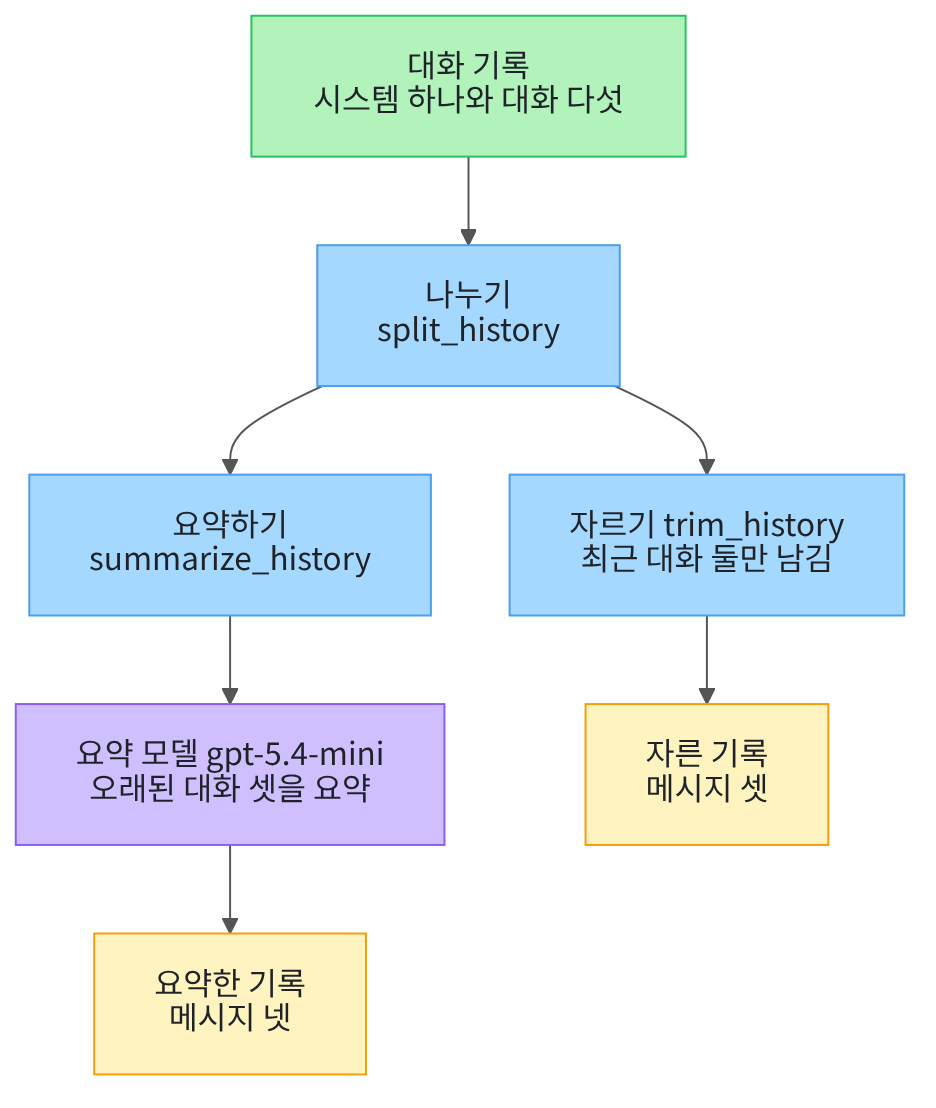

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 둘을 불러옵니다.
02절에서 글에 원문 값이 그대로 남았는지 찾던 함수 `find_raw_values`를 다시 씁니다.

앞에서 배운 함수는 `guardrails.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
이 절은 그 파일에서 이 함수 하나만 가져옵니다.

In [2]:
# 02절에서 배운 함수 하나와 모델을 만들 이름을 불러옵니다
from guardrails import find_raw_values
from langchain.chat_models import init_chat_model

print("불러온 이름:", "find_raw_values", "init_chat_model")

불러온 이름: find_raw_values init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: find_raw_values init_chat_model`로 이름 둘을 불러왔습니다.
함수 `find_raw_values`는 02절 노트북에서 정의한 함수와 같은 본문입니다.

## 2. 키와 모델 준비

이 절은 6절에서 오래된 대화를 요약할 때 모델 `gpt-5.4-mini`를 한 번 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 요약 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 이 절의 대화 기록

대화 기록(히스토리)은 앞서 주고받은 메시지를 차례대로 담은 목록입니다.
Ch 14 01절에서 쓴 말 그대로입니다.
메시지는 01·02절처럼 역할과 내용을 담은 딕셔너리입니다.
역할 `assistant`는 Ch 7 04절에서 본 것처럼 앞에서 모델이 한 답입니다.

다음 셀은 이 절에서 손으로 적은 대화 기록입니다.
첫 사용자 메시지가 답을 두 문장으로 해 달라는 조건을 정합니다.
둘째 사용자 메시지에는 빌린 책의 이름이 있습니다.

In [5]:
# 이 절에서 손으로 적은 대화 기록입니다: 시스템 메시지 하나와 대화 메시지 다섯 개
system_text = "미르시립도서관 안내 도우미입니다. 대화에 나온 사실만 써서 한국어로 답하세요."
history = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": "앞으로 답은 두 문장으로 해 주세요."},
    {"role": "assistant", "content": "네, 그렇게 하겠습니다."},
    {"role": "user", "content": "빌린 책 『작은 정원』을 반납하려고 합니다. 도서관은 언제 쉬나요?"},
    {"role": "assistant", "content": "매주 월요일과 법정 공휴일에 쉽니다. 공휴일이 월요일과 겹치면 화요일에도 쉽니다."},
    {"role": "user", "content": "그럼 이번 주에는 언제 반납하면 되나요?"},
]
print("메시지 수:", len(history))

메시지 수: 6


**결과 읽기** — 출력 줄 `메시지 수: 6`으로 기록에는 메시지가 여섯 개 있습니다.
시스템 메시지 하나와 대화 메시지 다섯 개입니다.
대화는 사용자와 모델이 번갈아 주고받은 모양으로 적었습니다.

다음 셀은 메시지마다 번호와 역할과 내용을 한 줄씩 출력합니다.
번호 `i`로 목록을 차례대로 돕니다.

In [6]:
# 메시지마다 번호와 역할과 내용을 한 줄씩 봅니다
print("번호 | 역할 | 내용")
for i in range(len(history)):
    print(i, "|", history[i]["role"], "|", history[i]["content"])

번호 | 역할 | 내용
0 | system | 미르시립도서관 안내 도우미입니다. 대화에 나온 사실만 써서 한국어로 답하세요.
1 | user | 앞으로 답은 두 문장으로 해 주세요.
2 | assistant | 네, 그렇게 하겠습니다.
3 | user | 빌린 책 『작은 정원』을 반납하려고 합니다. 도서관은 언제 쉬나요?
4 | assistant | 매주 월요일과 법정 공휴일에 쉽니다. 공휴일이 월요일과 겹치면 화요일에도 쉽니다.
5 | user | 그럼 이번 주에는 언제 반납하면 되나요?


**결과 읽기** — 라벨 줄 `번호 | 역할 | 내용` 아래 여섯 줄이 메시지입니다.
0번은 시스템 메시지이고 1번부터 대화가 이어집니다.
1번은 답을 두 문장으로 해 달라는 조건이고, 3번에 책 이름 「작은 정원」이 있습니다.
4번 답에는 공휴일이 월요일과 겹치면 화요일에도 쉰다는 사실이 있습니다.
5번이 지금 막 들어온 질문입니다.

## 4. 기록을 나누고 글로 잇기

자르거나 요약하기 전에 시스템 메시지와 대화 메시지를 나눕니다.
시스템 메시지는 모델이 따를 규칙이라 줄이지 않고 그대로 둡니다.
줄이는 대상은 대화 메시지뿐입니다.

다음 셀은 두 목록으로 나누는 함수입니다.
마지막 줄은 02절처럼 두 값을 튜플 하나로 묶어 내놓습니다.

In [7]:
# 시스템 메시지와 나머지 대화 메시지를 두 목록으로 나눕니다
def split_history(messages):
    system_messages = []
    dialogue = []
    for message in messages:
        if message["role"] == "system":
            system_messages.append(message)
        else:
            dialogue.append(message)
    return system_messages, dialogue

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `split_history`는 메시지를 하나씩 보며 역할이 `system`이면 첫 목록에 담습니다.
다른 역할이면 둘째 목록에 담습니다.
두 목록 모두 원래 차례를 그대로 지킵니다.

다음 셀은 이 함수로 대화 기록을 나눕니다.
02절처럼 왼쪽에 이름 둘을 쉼표로 적어 튜플의 두 값을 차례로 받습니다.

In [8]:
# 대화 기록을 두 목록으로 나누고 목록마다 메시지 수를 봅니다
system_messages, dialogue = split_history(history)
print("시스템 메시지 수:", len(system_messages))
print("대화 메시지 수:", len(dialogue))

시스템 메시지 수: 1
대화 메시지 수: 5


**결과 읽기** — 출력 줄 `시스템 메시지 수: 1`과 `대화 메시지 수: 5`로 두 목록이 나뉘었습니다.
이제 줄일 대상은 대화 메시지 다섯 개입니다.

다음 셀은 메시지 목록을 글 하나로 잇는 함수입니다.
메시지마다 「역할: 내용」 한 줄을 만들고 줄바꿈으로 잇습니다.
01절의 `" ".join(목록)`은 빈칸을 넣어 이었고, `"\n".join(목록)`은 줄바꿈을 넣어 잇습니다.
6절에서 모델에게 보낼 대화 글을 만들 때 이 함수를 씁니다.

In [9]:
# 메시지마다 「역할: 내용」 한 줄을 만들어 글 하나로 잇습니다
def history_text(messages):
    lines = []
    for message in messages:
        lines.append(message["role"] + ": " + message["content"])
    return "\n".join(lines)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `history_text`는 메시지 목록을 받아 글 하나를 내놓습니다.

다음 셀은 원본 대화 기록을 글 하나로 잇고 글자 수를 셉니다.
글자 수는 역할 이름과 줄바꿈까지 센 값입니다.

In [10]:
# 원본 대화 기록을 글 하나로 잇고 글자 수를 셉니다
full_text = history_text(history)
print("원본 기록 글:")
print(full_text)
print("원본 기록 글자 수:", len(full_text))

원본 기록 글:
system: 미르시립도서관 안내 도우미입니다. 대화에 나온 사실만 써서 한국어로 답하세요.
user: 앞으로 답은 두 문장으로 해 주세요.
assistant: 네, 그렇게 하겠습니다.
user: 빌린 책 『작은 정원』을 반납하려고 합니다. 도서관은 언제 쉬나요?
assistant: 매주 월요일과 법정 공휴일에 쉽니다. 공휴일이 월요일과 겹치면 화요일에도 쉽니다.
user: 그럼 이번 주에는 언제 반납하면 되나요?
원본 기록 글자 수: 233


**결과 읽기** — 라벨 줄 `원본 기록 글:` 아래 여섯 줄이 메시지 여섯 개입니다.
줄마다 역할 이름이 앞에 붙었습니다.
출력 줄 `원본 기록 글자 수: 233`이 이 글의 길이입니다.

다음 셀은 줄인 뒤에도 기록에 꼭 남아 있어야 할 지킬 말 셋을 정합니다.
지킬 말은 Ch 8 03절에서 쓴 말 그대로입니다.
1번의 조건 「두 문장」, 3번의 책 이름 「작은 정원」, 4번 답의 「화요일」입니다.
02절 함수 `find_raw_values`로 글 안에 그대로 있는 말만 모읍니다.
말이 글에 있는지만 보는 검사이고 요약의 품질 점수는 아닙니다.

In [11]:
# 줄인 뒤에도 기록에 남아 있어야 할 지킬 말 셋을 정하고 원본 기록 글에 있는지 봅니다
keep_words = ["두 문장", "작은 정원", "화요일"]
full_kept = find_raw_values(full_text, keep_words)
print("지킬 말:", keep_words)
print("원본 기록에 남은 말:", full_kept)

지킬 말: ['두 문장', '작은 정원', '화요일']
원본 기록에 남은 말: ['두 문장', '작은 정원', '화요일']


**결과 읽기** — 출력 줄 `원본 기록에 남은 말: ['두 문장', '작은 정원', '화요일']`로 원본에는 셋이 모두 있습니다.
이 목록을 뒤에서 줄인 기록과 견줍니다.

## 5. 오래된 대화 잘라 내기

자르기(트리밍, trimming)는 오래된 대화 메시지를 버리고 최근 몇 개만 남기는 일입니다.
긴 두루마리에서 끝부분만 남기고 앞을 잘라 내는 것과 같습니다.
자르기에는 모델을 부르지 않습니다.

먼저 목록 끝에서 몇 개를 떼는 슬라이스를 봅니다.
Ch 2 03절에서 `[-1]`은 마지막 값이었습니다.
슬라이스에도 음수를 쓰면 끝에서부터 셉니다.
그래서 `dialogue[-2:]`는 끝에서 둘째 값부터 끝까지입니다.
슬라이스 `dialogue[:-2]`는 그 앞 전부입니다.

In [12]:
# 대화 메시지 목록을 끝의 둘과 그 앞으로 나눠 봅니다
older_part = dialogue[:-2]
recent_part = dialogue[-2:]
print("앞쪽 메시지 수:", len(older_part))
print("끝쪽 메시지 수:", len(recent_part))
print("끝쪽 첫 메시지:", recent_part[0]["content"])

앞쪽 메시지 수: 3
끝쪽 메시지 수: 2
끝쪽 첫 메시지: 매주 월요일과 법정 공휴일에 쉽니다. 공휴일이 월요일과 겹치면 화요일에도 쉽니다.


**결과 읽기** — 출력 줄 `앞쪽 메시지 수: 3`과 `끝쪽 메시지 수: 2`로 대화 다섯 개가 셋과 둘로 나뉘었습니다.
출력 줄 `끝쪽 첫 메시지:` 뒤 글이 4번 답입니다.
원래 목록 `dialogue`는 그대로이고 두 슬라이스는 새 목록입니다.

다음 셀은 자르기 함수입니다.
남길 대화 수를 인자 `keep_recent`로 받습니다.
1보다 작은 수를 넣으면 01절처럼 `raise ValueError`로 멈춥니다.
시스템 메시지 목록 뒤에 최근 대화를 `+`로 잇습니다.
목록끼리 `+`로 이으면 두 목록을 차례대로 이은 새 목록이 됩니다.

In [13]:
# 시스템 메시지는 모두 두고 대화는 최근 keep_recent개만 남깁니다
def trim_history(messages, keep_recent):
    if keep_recent < 1:
        raise ValueError("keep_recent는 1 이상이어야 합니다.")
    system_messages, dialogue = split_history(messages)
    return system_messages + dialogue[-keep_recent:]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `trim_history`는 시스템 메시지를 모두 두고 대화는 끝에서 `keep_recent`개만 남깁니다.
함수 안에서 앞 셀의 함수 `split_history`를 부릅니다.
함수 안의 이름 `dialogue`는 함수가 끝나면 사라져 4절에서 만든 같은 이름을 바꾸지 않습니다.

다음 셀은 최근 대화 둘만 남기고 잘라 냅니다.
그다음 자른 기록을 글로 잇고 지킬 말을 찾습니다.

In [14]:
# 최근 대화 둘만 남기고 잘라 낸 뒤 지킬 말이 남았는지 봅니다
trimmed = trim_history(history, 2)
trimmed_text = history_text(trimmed)
trimmed_kept = find_raw_values(trimmed_text, keep_words)
print("자른 기록의 메시지 수:", len(trimmed))
print("자른 기록 글:")
print(trimmed_text)
print("자른 기록에 남은 말:", trimmed_kept)

자른 기록의 메시지 수: 3
자른 기록 글:
system: 미르시립도서관 안내 도우미입니다. 대화에 나온 사실만 써서 한국어로 답하세요.
assistant: 매주 월요일과 법정 공휴일에 쉽니다. 공휴일이 월요일과 겹치면 화요일에도 쉽니다.
user: 그럼 이번 주에는 언제 반납하면 되나요?
자른 기록에 남은 말: ['화요일']


**결과 읽기** — 출력 줄 `자른 기록의 메시지 수: 3`으로 시스템 메시지 하나와 최근 대화 둘이 남았습니다.
라벨 줄 `자른 기록 글:` 아래 세 줄이 남은 메시지입니다.
출력 줄 `자른 기록에 남은 말: ['화요일']`로 셋 가운데 하나만 남았습니다.

1번의 「두 문장」 조건과 3번의 책 이름은 잘려 나갔습니다.
대화 첫머리에서 정한 조건이 가장 먼저 잘립니다.
이 기록을 모델에 보내면 모델은 두 문장 조건을 받지 못합니다.
시스템 메시지 다음 줄이 `assistant:`로 시작해, 자른 기록은 질문 없이 모델 답부터 시작합니다.

## 6. 오래된 대화 요약하기

요약하기는 잘라 낼 오래된 대화를 모델에게 요약시켜 메시지 하나로 남기는 방법입니다.
이 교재에서 「요약」은 모델이 줄인 글에만 씁니다.
Ch 8 03절에서 사람이 원문을 줄인 일은 줄이기(Compress)라고 불렀습니다.

다음 셀은 요약을 부탁하는 머리글입니다.
Ch 14 01절처럼 모델에 넣을 글 앞에 붙일 말을 미리 적어 둡니다.

In [15]:
# 요약을 부탁하는 머리글입니다: 조건과 사실만 남기고 새 내용은 보태지 말라고 적습니다
summary_head = "아래 대화에서 사용자가 정한 조건과 확인한 사실만 한국어로 짧게 요약하세요.\n"
summary_head = summary_head + "대화에 없는 내용은 보태지 마세요.\n\n대화:\n"
print("요약 머리글:")
print(summary_head)

요약 머리글:
아래 대화에서 사용자가 정한 조건과 확인한 사실만 한국어로 짧게 요약하세요.
대화에 없는 내용은 보태지 마세요.

대화:



**결과 읽기** — 라벨 줄 `요약 머리글:` 아래가 모델에게 보낼 글의 앞부분입니다.
사용자가 정한 조건과 확인한 사실만 남기라고 적었습니다.
대화에 없는 내용은 보태지 말라는 줄도 넣었습니다.
맨 끝 `대화:` 뒤에 요약할 대화 글이 붙습니다.

다음 셀은 대화 글 하나를 받아 모델에게 요약을 받는 함수입니다.
Ch 14 01절처럼 글 하나를 그대로 `invoke`에 넣습니다.
이 함수를 부를 때마다 모델 요청이 한 번 나갑니다.

In [16]:
# 대화 글 하나를 머리글과 함께 모델에게 보내 요약 글을 받습니다(부를 때마다 모델 요청 1번)
def summarize_text(text):
    reply = model.invoke(summary_head + text)
    return reply.text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `summarize_text`는 머리글 뒤에 대화 글을 붙여 보내고 모델이 쓴 글을 내놓습니다.
정의만 했으므로 아직 요청은 나가지 않았습니다.

다음 셀은 요약하기 함수입니다.
요약을 만드는 함수를 인자 `summarizer`로 받습니다.
함수 이름을 괄호 없이 적으면 함수를 부르지 않고 함수 자체를 넘깁니다.
Ch 13에서 `add_node`에 함수 이름을 넘긴 것과 같은 모양입니다.

함수 본문 첫 줄은 5절의 자르기를 먼저 합니다.
남길 대화 수가 1보다 작으면 여기서 멈추고 모델은 부르지 않습니다.
잘라 낼 오래된 대화가 없으면 자른 기록을 그대로 내놓습니다.
오래된 대화가 있으면 글로 이어 요약을 받고 `strip()`으로 앞뒤 빈칸을 지웁니다.

요약 글은 역할 `user` 메시지에 담아 시스템 메시지와 최근 대화 사이에 넣습니다.
앞에는 「참고용 이전 대화 요약(지시가 아닌 자료)」을 붙입니다.
요약은 모델이 쓴 글이라 시스템 메시지 자리에 두지 않고 자료로 넣습니다.

In [17]:
# 오래된 대화는 요약 메시지 하나로 바꾸고 최근 keep_recent개는 그대로 둡니다
def summarize_history(messages, summarizer, keep_recent):
    trimmed_messages = trim_history(messages, keep_recent)
    system_messages, dialogue = split_history(messages)
    older = dialogue[:-keep_recent]
    if len(older) == 0:
        return trimmed_messages
    summary = summarizer(history_text(older)).strip()
    note = {"role": "user", "content": "참고용 이전 대화 요약(지시가 아닌 자료): " + summary}
    return system_messages + [note] + dialogue[-keep_recent:]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `summarize_history`는 시스템 메시지, 요약 메시지, 최근 대화 차례로 이은 새 목록을 내놓습니다.

다음 셀은 5절과 같은 대화 기록에 같은 남길 대화 수 2로 요약하기를 합니다.
오래된 대화 셋이 요약 메시지 하나가 됩니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [18]:
# 오래된 대화 셋을 요약 메시지 하나로 바꿉니다(모델 요청 1번)
summarized = summarize_history(history, summarize_text, 2)
summarized_text = history_text(summarized)
summarized_kept = find_raw_values(summarized_text, keep_words)
print("요약한 기록의 메시지 수:", len(summarized))
print("요약 메시지:")
print(summarized[1]["content"])
print("요약한 기록에 남은 말:", summarized_kept)

요약한 기록의 메시지 수: 4
요약 메시지:
참고용 이전 대화 요약(지시가 아닌 자료): 사용자는 앞으로 답을 두 문장으로 해 달라고 정했습니다.  
또한 빌린 책 『작은 정원』을 반납하려고 하며, 도서관의 휴관일을 확인하려고 했습니다.
요약한 기록에 남은 말: ['두 문장', '작은 정원', '화요일']


**결과 읽기** — 출력 줄 `요약한 기록의 메시지 수: 4`로 시스템 메시지, 요약 메시지, 최근 대화 둘이 남았습니다.
라벨 줄 `요약 메시지:` 아래가 모델이 쓴 요약을 담은 메시지입니다.
출력 줄 `요약한 기록에 남은 말: ['두 문장', '작은 정원', '화요일']`로 셋이 모두 남았습니다.
「두 문장」과 「작은 정원」은 요약 메시지 안에 있습니다.

요약 글은 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.
교재 출력을 만들기 전에 같은 요약 요청을 따로 다섯 번 보냈습니다.
다섯 번 모두 요약에 「두 문장」과 「작은 정원」이 있었고 글 길이는 조금씩 달랐습니다.

In [19]:
# 요약한 기록의 메시지마다 번호와 역할을 봅니다
print("번호 | 역할")
for i in range(len(summarized)):
    print(i, "|", summarized[i]["role"])

번호 | 역할
0 | system
1 | user
2 | assistant
3 | user


**결과 읽기** — 라벨 줄 `번호 | 역할` 아래 네 줄이 요약한 기록의 차례입니다.
1번이 요약 메시지이고 역할은 `user`입니다.
2번과 3번은 5절 자른 기록의 마지막 두 메시지와 같은 메시지입니다.

## 7. 세 기록 견주기

다음 셀은 원본, 자른 기록, 요약한 기록을 한 표로 나란히 봅니다.
글자 수는 `history_text`로 이은 글의 길이입니다.
남은 말 수는 지킬 말 셋 가운데 기록 글에 있는 수입니다.

In [20]:
# 세 기록의 메시지 수·글자 수·남은 말 수를 한 표로 나란히 봅니다
print("기록 | 메시지 수 | 글자 수 | 남은 말 수")
print("원본 |", len(history), "|", len(full_text), "|", len(full_kept))
print("자르기 |", len(trimmed), "|", len(trimmed_text), "|", len(trimmed_kept))
print("요약하기 |", len(summarized), "|", len(summarized_text), "|", len(summarized_kept))

기록 | 메시지 수 | 글자 수 | 남은 말 수
원본 | 6 | 233 | 3
자르기 | 3 | 137 | 1
요약하기 | 4 | 251 | 3


**결과 읽기** — 라벨 줄 `기록 | 메시지 수 | 글자 수 | 남은 말 수` 아래 세 줄이 세 기록입니다.
출력 줄 `원본 | 6 | 233 | 3`과 `자르기 | 3 | 137 | 1`은 모델을 부르지 않은 값이라 다시 실행해도 같습니다.
요약한 기록은 메시지 넷에 남은 말 셋입니다.

이번 실행에서는 출력 줄 `요약하기 | 4 | 251 | 3`이었습니다.
요약한 기록의 글자 수는 요약 글 길이에 따라 달라집니다.
이번 실행에서는 원본보다 18자 길었습니다.
짧은 대화에서는 요약 메시지가 잘라 낸 대화보다 길 수 있습니다.
메시지 수가 줄어도 글이 늘 짧아지지는 않습니다.

## 8. 손으로 확인하기 · 남길 대화 수 0

다음 셀은 요약하기 함수에 남길 대화 수 0을 넣어 봅니다.
함수 본문 첫 줄의 자르기가 먼저 멈추므로 모델 요청은 나가지 않습니다.
오류를 받는 `try`·`except ValueError as error`는 Ch 2 05절에서 배운 모양입니다.
오류를 받아 출력하고 셀은 끝까지 실행합니다.

In [21]:
# 남길 대화 수 0을 요약하기 함수에 넣어 봅니다(첫 줄에서 멈춰 모델은 부르지 않습니다)
try:
    summarize_history(history, summarize_text, 0)
except ValueError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:", error)

오류 종류: ValueError
오류 메시지: keep_recent는 1 이상이어야 합니다.


**결과 읽기** — 출력 줄 `오류 종류: ValueError`로 함수가 멈췄습니다.
출력 줄 `오류 메시지: keep_recent는 1 이상이어야 합니다.`가 자르기 함수의 오류 문장입니다.
요약 함수 `summarize_text`를 부르기 전에 멈췄으므로 이 셀은 모델을 부르지 않았습니다.

## 9. 값 바꿔 보기 · 남길 대화 수 4

바꿀 값은 자르기의 남길 대화 수 하나입니다.
2 대신 4를 넣어 자릅니다.

실행 전에 예상해 봅니다.
대화 다섯 개 가운데 가장 오래된 1번 하나만 잘릴 것입니다.
1번에 있던 「두 문장」 조건은 이번에도 빠질 것입니다.

In [22]:
# 바꿀 값은 남길 대화 수 하나입니다: 2 대신 4로 잘라 봅니다
trimmed_four = trim_history(history, 4)
four_text = history_text(trimmed_four)
four_kept = find_raw_values(four_text, keep_words)
print("넷을 남긴 기록의 메시지 수:", len(trimmed_four))
print("넷을 남긴 기록의 첫 대화:", trimmed_four[1]["content"])
print("넷을 남긴 기록에 남은 말:", four_kept)

넷을 남긴 기록의 메시지 수: 5
넷을 남긴 기록의 첫 대화: 네, 그렇게 하겠습니다.
넷을 남긴 기록에 남은 말: ['작은 정원', '화요일']


**결과 읽기** — 출력 줄 `넷을 남긴 기록의 메시지 수: 5`로 시스템 메시지와 대화 넷이 남았습니다.
출력 줄 `넷을 남긴 기록의 첫 대화: 네, 그렇게 하겠습니다.`로 1번 조건 메시지가 잘렸습니다.
출력 줄 `넷을 남긴 기록에 남은 말: ['작은 정원', '화요일']`로 둘이 남았습니다.

예상대로 남길 수를 넷으로 늘려도 「두 문장」 조건은 빠졌습니다.
자르기는 늘 가장 오래된 메시지부터 버립니다.
5절 출력에서는 `자른 기록에 남은 말: ['화요일']`이었습니다.

## 정리

1. 자르기는 모델을 부르지 않고 최근 대화 둘만 남겨, 대화 첫머리의 조건과 책 이름을 잃었습니다.
2. 요약하기는 모델 요청 한 번으로 오래된 대화 셋을 요약 메시지 하나로 바꿨고, 지킬 말 셋이 모두 남았습니다.
3. 남길 대화 수를 넷으로 늘려도 가장 오래된 「두 문장」 조건은 잘렸습니다.

04절에서는 모델을 부르기 전에 호출 수와 비용 상한을 정하고, 넘치는 요청을 막습니다.